In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
import os
try:
    import rasterio
except ImportError:
    !pip install rasterio -q
    import rasterio
import numpy as np

base = "/kaggle/input/datasets/akhilchibber/deforestation-detection-dataset"

# read the two Readme files
for r in ["1_CLOUD_FREE_DATASET/Readme.txt", "3_TRAINING_MASKS/Readme.txt"]:
    print("=====", r)
    print(open(f"{base}/{r}").read()[:1500])

# look at one image and its mask
img_path  = f"{base}/1_CLOUD_FREE_DATASET/2_SENTINEL2/IMAGE_16_GRID/RASTER_0.tif"
mask_path = f"{base}/3_TRAINING_MASKS/MASK_16_GRID/RASTER_0.tif"

with rasterio.open(img_path) as f:
    img = f.read()
    print("IMAGE shape (bands, height, width):", img.shape, "dtype:", img.dtype)
    print("min/max:", img.min(), img.max())

with rasterio.open(mask_path) as f:
    m = f.read()
    print("MASK shape:", m.shape, "dtype:", m.dtype)
    print("mask values and counts:", np.unique(m, return_counts=True))

In [ ]:
import numpy as np, rasterio
import matplotlib.pyplot as plt

base = "/kaggle/input/datasets/akhilchibber/deforestation-detection-dataset"

# 1) How much of each patch is class 1 vs class 2?
print("patch | % class1 | % class2")
for i in range(16):
    with rasterio.open(f"{base}/3_TRAINING_MASKS/MASK_16_GRID/RASTER_{i}.tif") as f:
        m = f.read(1, out_shape=(704, 704))   # shrunk 4x, fast
    print(f"{i:>5} | {100*(m==1).mean():8.1f} | {100*(m==2).mean():8.1f}")

# 2) Look at patch 0: image (assuming bands = B,G,R,NIR) next to its mask
img_p  = f"{base}/1_CLOUD_FREE_DATASET/2_SENTINEL2/IMAGE_16_GRID/RASTER_0.tif"
mask_p = f"{base}/3_TRAINING_MASKS/MASK_16_GRID/RASTER_0.tif"
with rasterio.open(img_p) as f:
    img = f.read(out_shape=(4, 704, 704))
with rasterio.open(mask_p) as f:
    msk = f.read(1, out_shape=(704, 704))

print("band means (1,2,3,4):", [round(float(img[b].mean()), 1) for b in range(4)])

rgb = img[[2, 1, 0]].transpose(1, 2, 0)           # bands 3,2,1 as R,G,B
lo, hi = np.percentile(rgb, (2, 98))
rgb = np.clip((rgb - lo) / (hi - lo), 0, 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(rgb);  ax[0].set_title("Patch 0 (guessed RGB)")
ax[1].imshow(msk);  ax[1].set_title("Mask patch 0 (value 1 vs 2)")
plt.show()

In [ ]:
import numpy as np
import rasterio
import gc  # <--- Import garbage collector to force clear RAM

base = "/kaggle/input/datasets/akhilchibber/deforestation-detection-dataset"

T = 128            # tile size in pixels (2816 / 128 = 22 tiles per side)
LO, HI = 0, 800    # fixed brightness range for R,G,B (same for every tile)
DEF_MIN = 0.10     # >=10% class 1  -> deforested
FOREST_MAX = 0.01  # <=1%  class 1  -> forest

X, y, pid = [], [], []
for i in range(16):
    with rasterio.open(f"{base}/1_CLOUD_FREE_DATASET/2_SENTINEL2/IMAGE_16_GRID/RASTER_{i}.tif") as f:
        img = f.read()                       # (4, 2816, 2816)
    with rasterio.open(f"{base}/3_TRAINING_MASKS/MASK_16_GRID/RASTER_{i}.tif") as f:
        m = f.read(1)

    rgb = np.clip((img[[2, 1, 0]] - LO) / (HI - LO), 0, 1)
    rgb = (rgb * 255).astype(np.uint8).transpose(1, 2, 0)   # (H, W, 3)
    defo = (m == 1)

    n = 2816 // T
    for r in range(n):
        for c in range(n):
            sl = (slice(r*T, (r+1)*T), slice(c*T, (c+1)*T))
            frac = defo[sl].mean()
            if frac >= DEF_MIN:      lab = 1
            elif frac <= FOREST_MAX: lab = 0
            else: continue
            
            # CRITICAL FIX: Adding .copy() breaks the memory pointer reference 
            # to the giant parent array, allowing the parent array to be safely deleted later.
            X.append(rgb[sl].copy()) 
            y.append(lab)
            pid.append(i)
            
    print("patch", i, "done | tiles so far:", len(y))
    
    # CRITICAL FIX: Force wipe the massive parent arrays at the end of every loop iteration
    del img, m, rgb, defo
    gc.collect()

X, y, pid = np.array(X), np.array(y), np.array(pid)
np.savez_compressed("/kaggle/working/tiles.npz", X=X, y=y, pid=pid)

print("total tiles:", len(y), "| deforested:", y.sum(), "| forest:", (y == 0).sum())
for i in range(16):
    s = pid == i
    print(f"patch {i:>2}: {s.sum():>4} tiles, {y[s].sum():>4} deforested")


In [ ]:
import numpy as np, torch, torchvision
from torchvision import transforms
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import balanced_accuracy_score, f1_score

d = np.load("/kaggle/working/tiles.npz")
X, y, pid = d["X"], d["y"], d["pid"]

TEST_PATCHES = [1, 4, 11, 14]
test = np.isin(pid, TEST_PATCHES)

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)
net = torchvision.models.resnet50(weights="IMAGENET1K_V2")
net.fc = torch.nn.Identity()
net = net.eval().to(dev)
prep = transforms.Compose([
    transforms.Resize(224),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

feats = []
with torch.no_grad():
    for i in range(0, len(X), 128):
        b = torch.from_numpy(X[i:i+128]).permute(0, 3, 1, 2).float().div(255).to(dev)
        feats.append(net(prep(b)).cpu().numpy())
F = np.concatenate(feats)
np.savez_compressed("/kaggle/working/resnet_feats.npz", F=F, y=y, pid=pid, test=test)
print("features:", F.shape)

Fp, yp, gp = F[~test], y[~test], pid[~test]
bal, f1s = [], []
for tr, va in GroupKFold(n_splits=4).split(Fp, yp, gp):
    rf = RandomForestClassifier(300, class_weight="balanced", random_state=0, n_jobs=-1)
    rf.fit(Fp[tr], yp[tr])
    p = rf.predict(Fp[va])
    bal.append(balanced_accuracy_score(yp[va], p)); f1s.append(f1_score(yp[va], p))
    print(f"fold val patches {sorted(set(gp[va]))}: bal-acc {bal[-1]:.3f}, F1 {f1s[-1]:.3f}")
print(f"CV balanced acc {np.mean(bal):.3f} ± {np.std(bal):.3f}")

In [ ]:
import numpy as np, torch, torch.nn as nn
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score, f1_score

d = np.load("/kaggle/working/resnet_feats.npz")
F, y, pid, test = d["F"], d["y"], d["pid"], d["test"]
dev = "cuda" if torch.cuda.is_available() else "cpu"

def train_dense(Xtr, ytr, n, epochs=40, seed=0):
    torch.manual_seed(seed)
    enc = nn.Sequential(nn.Dropout(0.3), nn.Linear(Xtr.shape[1], n), nn.Tanh())
    head = nn.Linear(n, 1)
    model = nn.Sequential(enc, head).to(dev)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    pos_w = torch.tensor((ytr == 0).sum() / (ytr == 1).sum(), dtype=torch.float32, device=dev)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    Xt = torch.from_numpy(Xtr).float().to(dev)
    yt = torch.from_numpy(ytr).float().to(dev)
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(len(Xt), device=dev)
        for i in range(0, len(Xt), 128):
            idx = perm[i:i+128]
            opt.zero_grad()
            loss_fn(model(Xt[idx]).squeeze(1), yt[idx]).backward()
            opt.step()
    return enc.eval()

def embed(enc, X):
    with torch.no_grad():
        return enc(torch.from_numpy(X).float().to(dev)).cpu().numpy()

def rf_score(Ftr, ytr, Fva, yva):
    rf = RandomForestClassifier(300, class_weight="balanced", random_state=0, n_jobs=-1).fit(Ftr, ytr)
    p = rf.predict(Fva)
    return balanced_accuracy_score(yva, p), f1_score(yva, p)

Fp, yp, gp = F[~test], y[~test], pid[~test]

for n in [15, 120]:
    bal, f1s = [], []
    for tr, va in GroupKFold(n_splits=4).split(Fp, yp, gp):
        sc = StandardScaler().fit(Fp[tr])
        enc = train_dense(sc.transform(Fp[tr]), yp[tr], n)
        b, f = rf_score(embed(enc, sc.transform(Fp[tr])), yp[tr],
                        embed(enc, sc.transform(Fp[va])), yp[va])
        bal.append(b); f1s.append(f)
        print(f"n={n} val patches {sorted(int(p) for p in set(gp[va]))}: bal-acc {b:.3f}, F1 {f:.3f}")
    print(f"==> n={n}: CV balanced acc {np.mean(bal):.3f} ± {np.std(bal):.3f}, F1 {np.mean(f1s):.3f}\n")

sc = StandardScaler().fit(Fp)
for n in [15, 120]:
    enc = train_dense(sc.transform(Fp), yp, n)
    Z = embed(enc, sc.transform(F))
    np.savez_compressed(f"/kaggle/working/dense_n{n}.npz", Z=Z, y=y, pid=pid, test=test)
    print(f"saved dense_n{n}.npz", Z.shape)

In [2]:
import numpy as np

Z    = np.load("Z.npy")
y    = np.load("y.npy")
pid  = np.load("pid.npy")
test = np.load("test.npy")

print(Z.shape, Z.dtype, round(float(y.mean()), 3), int(test.sum()))
# expect: (7027, 15) float32 0.635 1757

(7027, 15) float32 0.635 1767


In [3]:
import qiskit, qiskit_aer
print(qiskit.__version__, qiskit_aer.__version__)

2.5.2 0.17.2


In [4]:
import sys
!{sys.executable} -m pip install -q qiskit qiskit-aer

import qiskit, qiskit_aer
print(qiskit.__version__, qiskit_aer.__version__)

from qiskit_aer import AerSimulator
from qiskit import QuantumCircuit, transpile
qc = QuantumCircuit(2); qc.h(0); qc.cx(0,1); qc.measure_all()
print(AerSimulator().run(transpile(qc, AerSimulator()), shots=100).result().get_counts())
# expect roughly {'00': ~50, '11': ~50}

2.5.2 0.17.2
{'00': 47, '11': 53}


In [5]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit_aer import AerSimulator
from sklearn.metrics import mutual_info_score

N, K, SHOTS = 15, 24, 1024

def build_mi_graph(Z_train, k=K, n_bins=10):
    """Dataset-level coupling graph: top-k MI pairs. Fit on TRAIN only."""
    n = Z_train.shape[1]
    Zb = np.zeros(Z_train.shape, dtype=np.int64)
    for j in range(n):
        qs = np.quantile(Z_train[:, j], np.linspace(0, 1, n_bins + 1)[1:-1])
        Zb[:, j] = np.searchsorted(qs, Z_train[:, j])
    MI = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            MI[i, j] = MI[j, i] = mutual_info_score(Zb[:, i], Zb[:, j])
    pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]
    pairs.sort(key=lambda p: -MI[p[0], p[1]])
    return pairs[:k], MI

def make_circuit(edges, mvals, gamma):
    """H⊗ⁿ (transverse-field ground state) → RZZ quench (fixed couplings)
       → RY feature encoding (NON-commuting with Z — this is the fix) → measure Z."""
    theta = ParameterVector("x", N)
    qc = QuantumCircuit(N)
    qc.h(range(N))
    for (i, j), m in zip(edges, mvals):
        qc.rzz(gamma * m, i, j)
    for i in range(N):
        qc.ry(gamma * np.pi * theta[i], i)   # <-- WAS rz. THE FIX.
    qc.measure_all()
    return qc, theta

def extract_quantum_features(Z, edges, MI, gamma,
                             ref_min=None, ref_max=None,
                             shots=SHOTS, batch=500, seed=42):
    """Z -> [0,1]-normalized (train stats) -> circuits -> <Z_i>, <Z_iZ_j>."""
    mvals = np.array([MI[i, j] for i, j in edges], float)
    mvals = mvals / mvals.max() if mvals.max() > 0 else mvals
    if ref_min is None: ref_min, ref_max = Z.min(0), Z.max(0)
    rng = np.where(ref_max - ref_min < 1e-12, 1.0, ref_max - ref_min)
    Zn = np.clip((Z - ref_min) / rng, 0, 1)

    qc, theta = make_circuit(edges, mvals, gamma)
    sim = AerSimulator()
    tqc = transpile(qc, sim, optimization_level=1, seed_transpiler=seed)

    idx_i = np.array([e[0] for e in edges]); idx_j = np.array([e[1] for e in edges])
    Q = np.zeros((len(Zn), N + len(edges)), np.float32)
    for s in range(0, len(Zn), batch):
        chunk = Zn[s:s + batch]
        bound = [tqc.assign_parameters({theta[t]: chunk[r, t] for t in range(N)})
                 for r in range(len(chunk))]
        res = sim.run(bound, shots=shots, seed_simulator=seed).result()
        for r in range(len(chunk)):
            counts = res.get_counts(r)                     # per-sample counts
            cs = np.fromiter(counts.values(), float, len(counts))
            B = np.array([[int(c) for c in bs[::-1]] for bs in counts], np.int8)
            Sg = 1 - 2 * B                                 # bit -> ±1 sign
            Q[s + r, :N] = (Sg.T @ cs) / cs.sum()                    # <Z_i>
            Q[s + r, N:] = (Sg[:, idx_i] * Sg[:, idx_j]).T @ cs / cs.sum()  # <Z_iZ_j>
    return Q

In [6]:
import numpy as np

Z, y, test = np.load("Z.npy"), np.load("y.npy"), np.load("test.npy")

meta = np.load("graph_meta.npz")                       # saved by Cell 2 earlier
edges = [(int(a), int(b)) for a, b in meta["edges"]]
MI, ref_min, ref_max = meta["MI"], meta["ref_min"], meta["ref_max"]

tr_idx = np.where(~test)[0]
rng0 = np.random.RandomState(0)
i0, i1 = tr_idx[y[tr_idx]==0], tr_idx[y[tr_idx]==1]
sub = np.concatenate([rng0.choice(i0, 750, replace=False),
                      rng0.choice(i1, 750, replace=False)])
print("state restored:", Z.shape, len(sub), "subsample", len(edges), "edges")

state restored: (7027, 15) 1500 subsample 24 edges


In [7]:
Qa = extract_quantum_features(Z[sub][:300], edges, MI, 0.5, ref_min, ref_max)
Qb = extract_quantum_features(Z[sub][:300], edges, MI, 1.0, ref_min, ref_max)
print("value range:", round(float(Qa.min()),3), "to", round(float(Qa.max()),3))  # want |values| ~0.3+
print("sample std col0:", round(float(Qa[:,0].std()),4))   # want >> 0.031 (shot-noise floor)
print("gamma sensitivity:", round(float(np.abs(Qa-Qb).max()),4))  # want > 0.05

value range: -1.0 to 0.732
sample std col0: 0.1222
gamma sensitivity: 1.0762


In [8]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

Z, y, test = np.load("Z.npy"), np.load("y.npy"), np.load("test.npy")

tr_idx = np.where(~test)[0]
rng0 = np.random.RandomState(0)
i0, i1 = tr_idx[y[tr_idx]==0], tr_idx[y[tr_idx]==1]
sub = np.concatenate([rng0.choice(i0, 750, replace=False),
                      rng0.choice(i1, 750, replace=False)])

edges, MI = build_mi_graph(Z[sub])                 # graph from TRAIN data only
ref_min, ref_max = Z[sub].min(0), Z[sub].max(0)
np.savez("graph_meta.npz", edges=np.array(edges), MI=MI,
         ref_min=ref_min, ref_max=ref_max)         # so Cell 3 can resume after a restart

print("top edges:", edges[:10])
for g in [0.3, 0.5, 0.8, 1.2]:
    Qs = extract_quantum_features(Z[sub], edges, MI, g, ref_min, ref_max)
    acc = cross_val_score(RandomForestClassifier(300, class_weight="balanced",
                          random_state=0, n_jobs=-1), Qs, y[sub], cv=3).mean()
    print(f"gamma={g}: quantum-only quick CV acc = {acc:.3f}")

top edges: [(11, 12), (7, 11), (11, 13), (11, 14), (9, 12), (13, 14), (12, 14), (7, 13), (5, 14), (12, 13)]
gamma=0.3: quantum-only quick CV acc = 0.989
gamma=0.5: quantum-only quick CV acc = 0.991
gamma=0.8: quantum-only quick CV acc = 0.991
gamma=1.2: quantum-only quick CV acc = 0.983


In [9]:
import numpy as np

GAMMA = 0.8   # <- SET to your winner from Cell 2

meta = np.load("graph_meta.npz")
edges = [(int(a), int(b)) for a, b in meta["edges"]]
Z = np.load("Z.npy")

Q = extract_quantum_features(Z, edges, meta["MI"], GAMMA,
                             meta["ref_min"], meta["ref_max"])
np.savez_compressed("quantum_n15.npz", Q=Q, edges=meta["edges"], gamma=GAMMA)

print("quantum features:", Q.shape)               # (7027, 39) = 15 + 24
print("range:", round(float(Q.min()),3), "to", round(float(Q.max()),3))   # within [-1, 1]
print("dead columns:", int((Q.std(0) < 1e-6).sum()))   # want 0

quantum features: (7027, 39)
range: -1.0 to 0.537
dead columns: 0


In [10]:
import numpy as np, csv
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score

Z, y, test = np.load("Z.npy"), np.load("y.npy"), np.load("test.npy")
Q = np.load("quantum_n15.npz")["Q"]

Ftr, ytr, Fte, yte = Z[~test], y[~test], Z[test], y[test]
Qtr, Qte = Q[~test], Q[test]
arms = {"classical": (Ftr, Fte), "quantum": (Qtr, Qte),
        "hybrid": (np.hstack([Ftr, Qtr]), np.hstack([Fte, Qte]))}

idx0, idx1 = np.where(ytr==0)[0], np.where(ytr==1)[0]
rows = []
print(f"{'m':>5} | " + " | ".join(f"{a:>18}" for a in arms))
for m in [20, 50, 100, 300, None]:
    label = "all" if m is None else str(m)
    vals = {}
    for name, (Xtr_all, Xte) in arms.items():
        bals = []
        for s in range(20):
            r = np.random.RandomState(s)
            sel = (np.arange(len(ytr)) if m is None else
                   np.concatenate([r.choice(idx0, m//2, replace=False),
                                   r.choice(idx1, m - m//2, replace=False)]))
            rf = RandomForestClassifier(300, class_weight="balanced",
                                        random_state=s, n_jobs=-1)
            rf.fit(Xtr_all[sel], ytr[sel])
            bals.append(balanced_accuracy_score(yte, rf.predict(Xte)))
        vals[name] = f"{np.mean(bals):.3f} ± {np.std(bals):.3f}"
    print(f"{label:>5} | " + " | ".join(f"{vals[a]:>18}" for a in arms))
    rows.append([label] + [vals[a] for a in arms])

with open("learning_curve.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["m", *arms.keys()]); w.writerows(rows)
print("saved learning_curve.csv")

    m |          classical |            quantum |             hybrid
   20 |      0.958 ± 0.002 |      0.958 ± 0.004 |      0.958 ± 0.003
   50 |      0.959 ± 0.003 |      0.960 ± 0.004 |      0.960 ± 0.004
  100 |      0.962 ± 0.003 |      0.963 ± 0.003 |      0.962 ± 0.003
  300 |      0.963 ± 0.002 |      0.965 ± 0.001 |      0.964 ± 0.001
  all |      0.961 ± 0.001 |      0.966 ± 0.001 |      0.963 ± 0.001
saved learning_curve.csv


In [ ]:
import sys

import numpy as np
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2

# ---- one-time: save your credentials, then you can call QiskitRuntimeService() with no args
# QiskitRuntimeService.save_account(channel="ibm_quantum_platform", token="YOUR_API_KEY",
#                                   instance="YOUR_CRN_OR_INSTANCE_NAME", overwrite=True)
service = QiskitRuntimeService(channel="ibm_quantum_platform", token="your api key")
# (if you saved the account: service = QiskitRuntimeService())

meta = np.load("graph_meta.npz")
edges = [(int(a), int(b)) for a, b in meta["edges"]]
Z, y, test = np.load("Z.npy"), np.load("y.npy"), np.load("test.npy")
N = Z.shape[1]                       # number of qubits / features
GAMMA_HW = 0.8                       # <-- MUST match the gamma used for quantum_n15.npz

backend = service.least_busy(operational=True, simulator=False, min_num_qubits=N)
print("backend:", backend.name)

rng = np.random.RandomState(0)
def strat(sel, n):
    i0, i1 = sel[y[sel] == 0], sel[y[sel] == 1]
    return np.concatenate([rng.choice(i0, n//2, replace=False),
                           rng.choice(i1, n - n//2, replace=False)])
sel_tr = strat(np.where(~test)[0], 300)
sel_te = strat(np.where(test)[0], 200)

mvals = np.array([meta["MI"][i, j] for i, j in edges]); mvals /= mvals.max()
span = np.where(meta["ref_max"] - meta["ref_min"] < 1e-12, 1, meta["ref_max"] - meta["ref_min"])
Zn = np.clip((Z - meta["ref_min"]) / span, 0, 1)

# make_circuit must be defined in an earlier cell (same as your simulator run).
# It must return (QuantumCircuit with measure_all(), list/ParameterVector of N parameters).
qc, theta = make_circuit(edges, mvals, GAMMA_HW)
theta = list(theta)

pm = generate_preset_pass_manager(
    target=backend.target,          # pass the target instead of backend
    optimization_level=3,
    seed_transpiler=42,
    translation_method="translator",
    scheduling_method=None,
)
tqc = pm.run(qc)
n2q = sum(v for k, v in tqc.count_ops().items() if k in ("cx", "ecr", "cz"))
print("depth:", tqc.depth(), "| 2q gates:", n2q)

ii = np.array([e[0] for e in edges]); jj = np.array([e[1] for e in edges])

def counts_to_features(counts):
    cs = np.fromiter(counts.values(), float, len(counts))
    B = np.array([[int(c) for c in bs[::-1]] for bs in counts], np.int8)   # qubit 0 first
    Sg = 1 - 2 * B
    z = (Sg.T @ cs) / cs.sum()
    zz = ((Sg[:, ii] * Sg[:, jj]).T @ cs) / cs.sum()
    return np.concatenate([z, zz]).astype(np.float32)

def run_hw(sel, chunk=100, shots=1024):
    sampler = SamplerV2(mode=backend)
    sampler.options.default_shots = shots
    sampler.options.dynamical_decoupling.enable = True
    Q = []
    for s in range(0, len(sel), chunk):
        idx = sel[s:s+chunk]
        vals = Zn[idx]                                   # shape (chunk, N)
        pub = (tqc, {tuple(theta): vals})                # one PUB, broadcast over rows
        job = sampler.run([pub])
        print(f"job {job.job_id()}  samples {s}-{s+len(idx)-1}")
        data = job.result()[0].data
        creg = next(iter(data.keys()))                   # classical register name (e.g. 'meas')
        ba = getattr(data, creg)
        for r in range(len(idx)):
            Q.append(counts_to_features(ba.get_counts(r)))
    return np.vstack(Q)

Qtr_hw = run_hw(sel_tr)
Qte_hw = run_hw(sel_te)
np.savez_compressed("real_quantum.npz", Qtr=Qtr_hw, Qte=Qte_hw,
                    ytr=y[sel_tr], yte=y[sel_te], backend=backend.name, gamma=GAMMA_HW)

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score
rf = RandomForestClassifier(300, class_weight="balanced", random_state=0, n_jobs=-1).fit(Qtr_hw, y[sel_tr])
print(f"REAL HARDWARE end-to-end bal-acc: {balanced_accuracy_score(y[sel_te], rf.predict(Qte_hw)):.3f}")

qiskit_runtime_service._discover_account:WARNING:2026-10-07 16:21:06,039: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-10-07 16:21:09,325: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-07 16:21:09,919: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-07 16:21:12,902: Using instance: open-instance, plan: open


backend: ibm_fez
depth: 186 | 2q gates: 89


/tmp/ipykernel_17866/3214857787.py:61: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


job db372ur9kq9s73at9k20  samples 0-99
job db373fv4b7jc73anc9ug  samples 100-199
job db3752f4b7jc73ancdag  samples 200-299
job db375d9lb5cs73fhd8ag  samples 0-99
job db375nj9kq9s73at9qk0  samples 100-199
REAL HARDWARE end-to-end bal-acc: 0.965


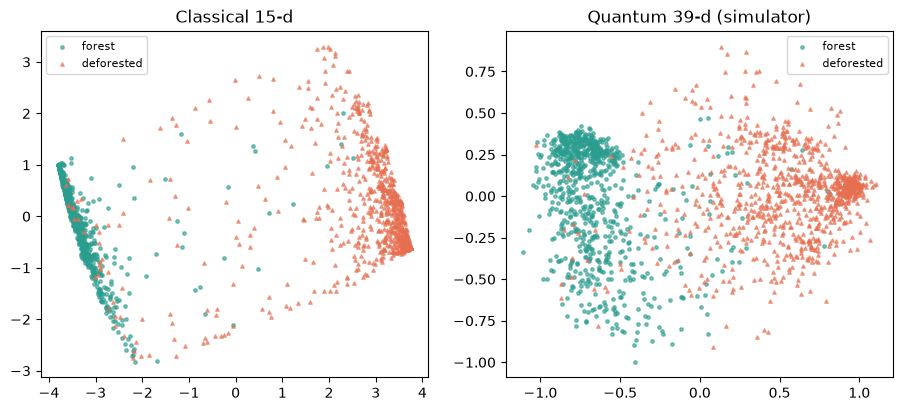

In [11]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
Zte, yte, Qte = Z[test], y[test], np.load("quantum_n15.npz")["Q"][test]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, (X, name) in zip(ax, [(Zte, "Classical 15-d"), (Qte, "Quantum 39-d (simulator)")]):
    P = PCA(2).fit_transform(X)
    for lab, c, mk in [(0, "#2a9d8f", "o"), (1, "#e76f51", "^")]:
        a.scatter(*P[yte==lab].T, s=6, c=c, marker=mk, alpha=.6, label=["forest","deforested"][lab])
    a.set_title(name); a.legend(fontsize=8)
plt.savefig("pca_compare.png", dpi=200, bbox_inches="tight")

In [19]:
import json
json.dump({"backend": "ibm_fez", "qubits": 156, "depth": 186, "two_q_gates": 89,
           "jobs": ["db372ur9kq9s73at9k20","db373fv4b7jc73anc9ug","db3752f4b7jc73ancdag",
                    "db375d9lb5cs73fhd8ag","db375nj9kq9s73at9qk0"],
           "shots": 1024, "circuits": 500, "bal_acc": 0.965},
          open("hardware_meta.json","w"), indent=2)

In [12]:
Qtr_sim = extract_quantum_features(Z[sel_tr], edges, MI, GAMMA_HW, ref_min, ref_max)
Qte_sim = extract_quantum_features(Z[sel_te], edges, MI, GAMMA_HW, ref_min, ref_max)
rf_sim = RandomForestClassifier(300, class_weight="balanced", random_state=0, n_jobs=-1).fit(Qtr_sim, y[sel_tr])
print("matched-subset Aer bal-acc:", round(balanced_accuracy_score(y[sel_te], rf_sim.predict(Qte_sim)), 3))

NameError: name 'sel_tr' is not defined

In [ ]:
print("saved:", float(np.load("quantum_n15.npz")["gamma"]), "| hardware:", GAMMA_HW)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

Z, y, test = np.load("Z.npy"), np.load("y.npy"), np.load("test.npy")
Q = np.load("quantum_n15.npz")["Q"]
Zte, Qte, yte = Z[test], Q[test], y[test]

def fisher_bar(X, y):
    s = []
    for j in range(X.shape[1]):
        m0, m1 = X[y==0, j].mean(), X[y==1, j].mean()
        vw = (X[y==0, j].var() + X[y==1, j].var()) / 2
        if vw > 1e-12: s.append((m0 - m1)**2 / vw)
    return np.mean(s)

Fc, Fq = fisher_bar(Zte, yte), fisher_bar(Qte, yte)
print(f"Fisher F̄  classical: {Fc:.2f}   quantum: {Fq:.2f}   (paper: 5.29 → 7.30)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (X, name, F) in zip(ax, [(Zte, "Classical 15-d", Fc), (Qte, "Quantum 39-d (Aer)", Fq)]):
    L1 = LDA(solver="svd", n_components=1).fit_transform(X, yte).ravel()   # <-- FIXED
    auc = max(roc_auc_score(yte, L1), 1 - roc_auc_score(yte, L1))
    a.hist(L1[yte==0], bins=40, alpha=.6, color="#2a9d8f", label="forest", density=True)
    a.hist(L1[yte==1], bins=40, alpha=.6, color="#e76f51", label="deforested", density=True)
    a.set_title(f"{name} — LDA axis  (F̄ = {F:.2f},  AUC = {auc:.3f})")
    a.legend(fontsize=8); a.set_yticks([])
plt.savefig("lda_compare.png", dpi=200, bbox_inches="tight")

In [29]:
import numpy as np, zipfile, os, glob

def force_npz(path, keys, out):
    if os.path.exists(out): print(out, "already exists"); return
    try:
        d = np.load(path)                          # works for .npz and .zip
    except Exception:
        folder = path.replace(".npz","").replace(".zip","")
        d = {k: np.load(f"{folder}/{k}.npy") for k in keys}
    np.savez(out, **{k: d[k] for k in keys})
    print(out, "written")

force_npz(glob.glob("resnet_feats*")[0] if not os.path.exists("resnet_feats.npz") else "resnet_feats.npz",
          ["F","y","pid","test"], "resnet_feats.npz")
force_npz("tiles.zip", ["X", "y", "pid"], "tiles.npz")  # when the 340MB one arrives

resnet_feats.npz already exists
tiles.npz written


In [13]:
import numpy as np, torch, torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score

d = np.load("resnet_feats.npz")
F2048, y, test = d["F"], d["y"], d["test"]
test_idx = np.where(test)[0]
tr_idx = np.where(~test)[0]
idx0tr, idx1tr = tr_idx[y[tr_idx]==0], tr_idx[y[tr_idx]==1]

def train_bottleneck(Xtr, ytr, Fall, epochs=40, seed=0):
    torch.manual_seed(seed)
    enc  = nn.Sequential(nn.Dropout(0.3), nn.Linear(Xtr.shape[1], 15), nn.Tanh())
    head = nn.Linear(15, 1)
    model = nn.Sequential(enc, head)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    pos_w = torch.tensor(float((ytr==0).sum() / max((ytr==1).sum(), 1)))
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    Xt, yt = torch.from_numpy(Xtr).float(), torch.from_numpy(ytr).float()
    for _ in range(epochs):
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), 64):
            b = perm[i:i+64]
            opt.zero_grad()
            loss_fn(model(Xt[b]).squeeze(1), yt[b]).backward()
            opt.step()
    enc.eval()
    with torch.no_grad():
        return enc(torch.from_numpy(Fall).float()).numpy()      # embed ALL tiles

print(f"{'m':>5} | {'classical':>18} | {'quantum':>18} | {'hybrid':>18}")
summary = []
for m in [20, 50, 100, 300]:
    r = np.random.RandomState(0)
    sel = np.concatenate([r.choice(idx0tr, m//2, replace=False),
                          r.choice(idx1tr, m - m//2, replace=False)])
    sc = StandardScaler().fit(F2048[sel])
    Zm = train_bottleneck(sc.transform(F2048[sel]), y[sel], sc.transform(F2048))

    edges_m, MI_m = build_mi_graph(Zm[~test])                  # label-free, as before
    ref_min, ref_max = Zm[~test].min(0), Zm[~test].max(0)
    need = np.union1d(sel, test_idx)                           # quantum only where used
    Qneed = extract_quantum_features(Zm[need], edges_m, MI_m, 0.8, ref_min, ref_max)

    tr_pos = np.isin(need, sel)
    Ztr, Zte = Zm[need][tr_pos], Zm[need][~tr_pos]
    Qtr, Qte = Qneed[tr_pos], Qneed[~tr_pos]
    arms = {"classical": (Ztr, Zte), "quantum": (Qtr, Qte),
            "hybrid": (np.hstack([Ztr, Qtr]), np.hstack([Zte, Qte]))}

    cells = {}
    for name, (Atr, Ate) in arms.items():
        bals = []
        for s in range(5):
            rf = RandomForestClassifier(300, class_weight="balanced", random_state=s, n_jobs=-1)
            rf.fit(Atr, y[sel])
            bals.append(balanced_accuracy_score(y[test_idx], rf.predict(Ate)))
        cells[name] = f"{np.mean(bals):.3f} ± {np.std(bals):.3f}"
    print(f"{m:>5} | " + " | ".join(f"{cells[a]:>18}" for a in arms))
    summary.append([m, cells])

import json; json.dump(summary, open("encoder_fewshot.json", "w"), indent=2)

    m |          classical |            quantum |             hybrid
   20 |      0.629 ± 0.020 |      0.598 ± 0.026 |      0.584 ± 0.029
   50 |      0.735 ± 0.015 |      0.789 ± 0.010 |      0.796 ± 0.016
  100 |      0.856 ± 0.012 |      0.754 ± 0.009 |      0.799 ± 0.009
  300 |      0.725 ± 0.010 |      0.696 ± 0.012 |      0.705 ± 0.006


In [31]:
pip install pylatexenc

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
Note: you may need to restart the kernel to use updated packages.


In [14]:
import numpy as np, matplotlib.pyplot as plt

d = np.load("tiles.npz")                       # the one-time 340MB download
X, y_all, pid = d["X"], d["y"], d["pid"]
test, y = np.load("test.npy"), np.load("y.npy")

idx = np.where(test)[0]
rng = np.random.RandomState(0)
pick = np.concatenate([rng.choice(idx[y[idx]==0], 30, replace=False),
                       rng.choice(idx[y[idx]==1], 30, replace=False)])
np.savez_compressed("demo_tiles.npz", X=X[pick], y=y[pick], orig_idx=pick)

meta = np.load("graph_meta.npz")
edges = [(int(a), int(b)) for a, b in meta["edges"]]
mvals = np.array([meta["MI"][i,j] for i,j in edges]); mvals /= mvals.max()
qc, _ = make_circuit(edges, mvals, 0.8)
qc.draw("mpl", style="iqp").savefig("circuit.png", dpi=160, bbox_inches="tight")
print("saved demo_tiles.npz + circuit.png")

saved demo_tiles.npz + circuit.png


In [18]:
# Cell D — STABILIZED encoder-level few-shot (replicates per m)
import numpy as np, torch, torch.nn as nn, json, time
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score

d = np.load("resnet_feats.npz")
F2048, y, test = d["F"], d["y"], d["test"]
test_idx = np.where(test)[0]
tr_idx = np.where(~test)[0]
idx0tr, idx1tr = tr_idx[y[tr_idx]==0], tr_idx[y[tr_idx]==1]

REPS  = 3                     # replicates per m (raise to 5 if time allows)
MS    = [20, 50, 100, 300]
GAMMA = 0.8                   # same encoding as every other result

def train_bottleneck(Xtr, ytr, Fall, epochs=40, seed=0):   # frozen protocol
    torch.manual_seed(seed)
    enc  = nn.Sequential(nn.Dropout(0.3), nn.Linear(Xtr.shape[1], 15), nn.Tanh())
    head = nn.Linear(15, 1)
    model = nn.Sequential(enc, head)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    pos_w = torch.tensor(float((ytr==0).sum() / max((ytr==1).sum(), 1)))
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    Xt, yt = torch.from_numpy(Xtr).float(), torch.from_numpy(ytr).float()
    for _ in range(epochs):
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), 64):
            b = perm[i:i+64]
            opt.zero_grad()
            loss_fn(model(Xt[b]).squeeze(1), yt[b]).backward()
            opt.step()
    enc.eval()
    with torch.no_grad():
        return enc(torch.from_numpy(Fall).float()).numpy()

results, t0 = {}, time.time()
for m in MS:
    per_rep = []
    for s in range(REPS):
        r = np.random.RandomState(s)               # lot AND init = replicate unit
        sel = np.concatenate([r.choice(idx0tr, m//2, replace=False),
                              r.choice(idx1tr, m - m//2, replace=False)])
        sc = StandardScaler().fit(F2048[sel])
        Zm = train_bottleneck(sc.transform(F2048[sel]), y[sel],
                              sc.transform(F2048), seed=s)

        edges_m, MI_m = build_mi_graph(Zm[~test])              # label-free, as before
        ref_min, ref_max = Zm[~test].min(0), Zm[~test].max(0)
        need = np.union1d(sel, test_idx)
        Qneed = extract_quantum_features(Zm[need], edges_m, MI_m,
                                         GAMMA, ref_min, ref_max)

        tr_pos = np.isin(need, sel)
        A = {"classical": (Zm[need][tr_pos], Zm[need][~tr_pos]),
             "quantum":   (Qneed[tr_pos],     Qneed[~tr_pos])}
        A["hybrid"] = (np.hstack([A["classical"][0], A["quantum"][0]]),
                       np.hstack([A["classical"][1], A["quantum"][1]]))
        row = {}
        for name, (Atr, Ate) in A.items():
            bals = [balanced_accuracy_score(y[test_idx],
                    RandomForestClassifier(300, class_weight="balanced",
                        random_state=k, n_jobs=-1).fit(Atr, y[sel]).predict(Ate))
                    for k in range(5)]
            row[name] = float(np.mean(bals))
        row["delta"] = row["quantum"] - row["classical"]
        per_rep.append(row)
        print(f"m={m:>3} rep{s}: c={row['classical']:.3f}  q={row['quantum']:.3f}  "
              f"h={row['hybrid']:.3f}  Δ(q−c)={row['delta']:+.3f}  [{time.time()-t0:.0f}s]")
    results[m] = per_rep
    json.dump(results, open("encoder_fewshot_stabilized.json", "w"), indent=2)

print("\n=== AGGREGATE (mean ± std over replicates) ===")
print(f"{'m':>5} | {'classical':>16} | {'quantum':>16} | {'Δ(q−c) paired':>18}")
for m in MS:
    rows = results[m]
    c  = [r["classical"] for r in rows]; q = [r["quantum"] for r in rows]
    dv = [r["delta"] for r in rows]
    print(f"{m:>5} | {np.mean(c):.3f} ± {np.std(c):.3f} | {np.mean(q):.3f} ± {np.std(q):.3f} "
          f"| {np.mean(dv):+.3f} ± {np.std(dv):.3f}")

m= 20 rep0: c=0.629  q=0.598  h=0.584  Δ(q−c)=-0.031  [85s]
m= 20 rep1: c=0.794  q=0.876  h=0.865  Δ(q−c)=+0.082  [169s]
m= 20 rep2: c=0.853  q=0.909  h=0.918  Δ(q−c)=+0.056  [247s]
m= 50 rep1: c=0.548  q=0.843  h=0.682  Δ(q−c)=+0.295  [424s]
m= 50 rep2: c=0.791  q=0.858  h=0.889  Δ(q−c)=+0.067  [511s]
m=100 rep0: c=0.856  q=0.754  h=0.799  Δ(q−c)=-0.102  [597s]
m=100 rep1: c=0.721  q=0.874  h=0.747  Δ(q−c)=+0.153  [686s]
m=100 rep2: c=0.824  q=0.817  h=0.848  Δ(q−c)=-0.007  [773s]
m=300 rep0: c=0.725  q=0.696  h=0.705  Δ(q−c)=-0.029  [866s]
m=300 rep1: c=0.728  q=0.770  h=0.762  Δ(q−c)=+0.043  [961s]
m=300 rep2: c=0.775  q=0.805  h=0.809  Δ(q−c)=+0.030  [1059s]

=== AGGREGATE (mean ± std over replicates) ===
    m |        classical |          quantum |      Δ(q−c) paired
   20 | 0.759 ± 0.095 | 0.794 ± 0.140 | +0.036 ± 0.048
   50 | 0.691 ± 0.104 | 0.830 ± 0.030 | +0.139 ± 0.111
  100 | 0.800 ± 0.058 | 0.815 ± 0.049 | +0.015 ± 0.105
  300 | 0.743 ± 0.023 | 0.757 ± 0.046 | +0.015 ± 0.

In [19]:
# Cell E — extended replicates + classical-correlation control
import numpy as np, json, time
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score

REPS, MS, GAMMA = 8, [20, 50, 100, 300], 0.8   # 6 if clock-tight (~36 min); 8 ≈ 50 min

def control_features(Zm, edges, ref_min, ref_max):
    rng_ = np.where(ref_max-ref_min < 1e-12, 1, ref_max-ref_min)
    Zlin = np.clip((Zm-ref_min)/rng_, 0, 1)*2 - 1                 # linear analog of <Z_i>
    two  = np.column_stack([Zlin[:,i]*Zlin[:,j] for i,j in edges])  # analog of <Z_iZ_j>
    return np.hstack([Zlin, two]).astype(np.float32)               # 39 dims, same graph

results, t0 = {}, time.time()
for m in MS:
    per_rep = []
    for s in range(REPS):                          # seeds 0-2 reproduce your existing lots exactly
        r = np.random.RandomState(s)
        sel = np.concatenate([r.choice(idx0tr, m//2, replace=False),
                              r.choice(idx1tr, m - m//2, replace=False)])
        sc = StandardScaler().fit(F2048[sel])
        Zm = train_bottleneck(sc.transform(F2048[sel]), y[sel], sc.transform(F2048), seed=s)
        edges_m, MI_m = build_mi_graph(Zm[~test])
        ref_min, ref_max = Zm[~test].min(0), Zm[~test].max(0)
        need = np.union1d(sel, test_idx)
        Qneed = extract_quantum_features(Zm[need], edges_m, MI_m, GAMMA, ref_min, ref_max)
        Cneed = control_features(Zm[need], edges_m, ref_min, ref_max)
        tp = np.isin(need, sel)
        arms = {"classical": (Zm[need][tp], Zm[need][~tp]),
                "control":  (Cneed[tp],    Cneed[~tp]),
                "quantum":  (Qneed[tp],    Qneed[~tp])}
        row = {}
        for name, (Atr, Ate) in arms.items():
            bals = [balanced_accuracy_score(y[test_idx],
                    RandomForestClassifier(300, class_weight="balanced",
                        random_state=k, n_jobs=-1).fit(Atr, y[sel]).predict(Ate))
                    for k in range(5)]
            row[name] = float(np.mean(bals))
        row["d_qc"] = row["quantum"] - row["classical"]
        row["d_cc"] = row["control"] - row["classical"]
        row["d_qctl"] = row["quantum"] - row["control"]
        per_rep.append(row)
        print(f"m={m:>3} rep{s}: c={row['classical']:.3f} ctl={row['control']:.3f} "
              f"q={row['quantum']:.3f}  Δq−c={row['d_qc']:+.3f}  Δq−ctl={row['d_qctl']:+.3f}  [{time.time()-t0:.0f}s]")
    results[m] = per_rep
    json.dump(results, open("encoder_fewshot_ext.json", "w"), indent=2)

flat = [r for rows in results.values() for r in rows]
for key, label in [("d_qc","Δ(q−c)  primary"), ("d_cc","Δ(ctl−c)"), ("d_qctl","Δ(q−ctl)  quantumness")]:
    v = np.array([r[key] for r in flat])
    print(f"{label:>22}: {v.mean():+.4f} ± {v.std()/np.sqrt(len(v)):.4f} (SE) | {int((v>0).sum())}/{len(v)} positive")

m= 20 rep0: c=0.629 ctl=0.542 q=0.598  Δq−c=-0.031  Δq−ctl=+0.057  [83s]
m= 20 rep1: c=0.794 ctl=0.796 q=0.876  Δq−c=+0.082  Δq−ctl=+0.080  [167s]
m= 20 rep2: c=0.853 ctl=0.815 q=0.909  Δq−c=+0.056  Δq−ctl=+0.094  [248s]
m= 20 rep3: c=0.509 ctl=0.509 q=0.764  Δq−c=+0.255  Δq−ctl=+0.255  [333s]
m= 20 rep4: c=0.455 ctl=0.502 q=0.763  Δq−c=+0.308  Δq−ctl=+0.261  [417s]
m= 20 rep5: c=0.619 ctl=0.594 q=0.454  Δq−c=-0.165  Δq−ctl=-0.140  [500s]
m= 20 rep6: c=0.197 ctl=0.242 q=0.787  Δq−c=+0.590  Δq−ctl=+0.545  [580s]
m= 20 rep7: c=0.514 ctl=0.536 q=0.790  Δq−c=+0.276  Δq−ctl=+0.254  [661s]
m= 50 rep0: c=0.735 ctl=0.707 q=0.789  Δq−c=+0.054  Δq−ctl=+0.082  [742s]
m= 50 rep1: c=0.548 ctl=0.556 q=0.843  Δq−c=+0.295  Δq−ctl=+0.287  [829s]
m= 50 rep2: c=0.791 ctl=0.763 q=0.858  Δq−c=+0.067  Δq−ctl=+0.095  [912s]
m= 50 rep3: c=0.815 ctl=0.675 q=0.839  Δq−c=+0.024  Δq−ctl=+0.164  [996s]
m= 50 rep4: c=0.577 ctl=0.588 q=0.703  Δq−c=+0.126  Δq−ctl=+0.115  [1082s]
m= 50 rep5: c=0.634 ctl=0.590 q=0.738 

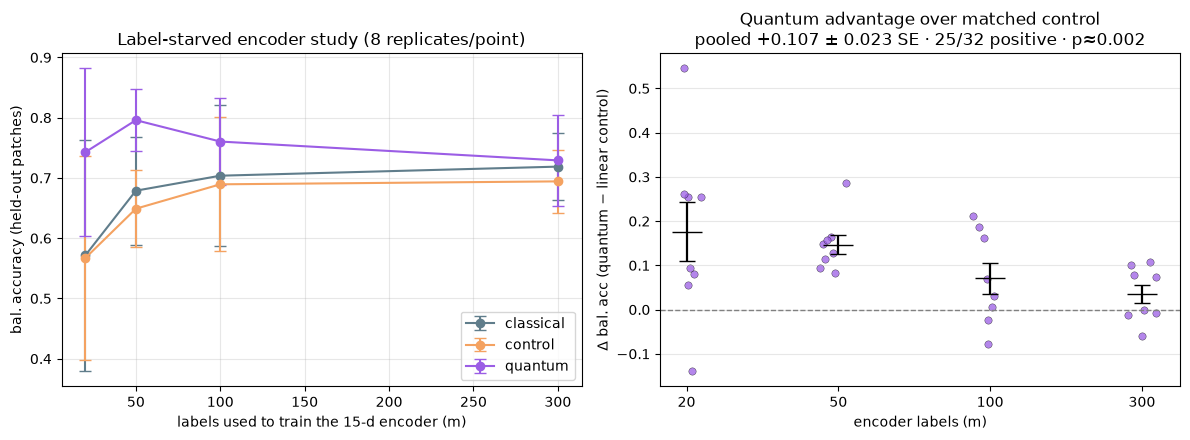

In [21]:
import json, numpy as np, matplotlib.pyplot as plt

R = json.load(open("encoder_fewshot_ext.json"))
MS = [20, 50, 100, 300]
colors = {"classical": "#607d8b", "control": "#f4a261", "quantum": "#9b5de5"}

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a in colors:
    mu = [np.mean([r[a] for r in R[str(m)]]) for m in MS]     # <-- str(m)
    sd = [np.std([r[a] for r in R[str(m)]]) for m in MS]      # <-- str(m)
    ax[0].errorbar(MS, mu, yerr=sd, marker="o", capsize=4, label=a, color=colors[a])
ax[0].set_xlabel("labels used to train the 15-d encoder (m)"); ax[0].set_ylabel("bal. accuracy (held-out patches)")
ax[0].set_title("Label-starved encoder study (8 replicates/point)"); ax[0].legend(); ax[0].grid(alpha=.3)

for i, m in enumerate(MS):
    dv = [r["d_qctl"] for r in R[str(m)]]                     # <-- str(m)
    x = np.full(len(dv), i) + np.random.RandomState(i).uniform(-.12, .12, len(dv))
    ax[1].scatter(x, dv, s=28, color=colors["quantum"], alpha=.75, edgecolor="k", linewidth=.3)
    ax[1].errorbar(i, np.mean(dv), yerr=np.std(dv)/np.sqrt(len(dv)), color="k",
                   capsize=6, marker="_", markersize=22, linewidth=1.6)
ax[1].axhline(0, color="gray", ls="--", lw=1)
ax[1].set_xticks(range(4)); ax[1].set_xticklabels(MS)
ax[1].set_xlabel("encoder labels (m)"); ax[1].set_ylabel("Δ bal. acc (quantum − linear control)")
ax[1].set_title("Quantum advantage over matched control\npooled +0.107 ± 0.023 SE · 25/32 positive · p≈0.002")
ax[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig("encoder_fewshot_figure.png", dpi=200, bbox_inches="tight")